# 03 · H&E morphology and within-slide concordance

For every spot we measure simple image features on a crop of the hires H&E image around the spot
(about two spot diameters, ~27 px):

- **hematoxylin_od, eosin_od**: mean optical density after color deconvolution. Hematoxylin
  marks nuclei; eosin marks cytoplasm and stroma.
- **gray_mean, gray_sd**: brightness and its spread.
- **glcm_\***: gray-level co-occurrence statistics (contrast, dissimilarity, homogeneity, energy,
  correlation), averaged over distances 1-2 px and four angles.

These numbers depend on staining and scanning, so a difference *between* the slides says little.
Instead we ask whether a molecular feature tracks an image feature *within* each slide, with the
same sign in both. Slide identity cannot produce such a pattern.

Scope: one normal and one cancer section from two donors. Differences between the slides mix biology with donor, processing and depth effects; see the [README](../README.md#scope).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prostate_markers import io, viz

config = io.load_config()
fig_dir = io.path(config, "figures")
viz.set_style()
pd.set_option("display.precision", 3)

In [2]:
between = io.read_table(config, "image_between_slides.csv")
between

,feature,mean_normal,mean_cancer,cohens_d,prob_superiority
0,hematoxylin_od,0.014,0.023,0.983,0.758
1,eosin_od,0.011,0.004,-1.727,0.122
2,gray_mean,0.658,0.711,1.146,0.817
3,gray_sd,0.112,0.111,-0.027,0.534
4,glcm_contrast,13.705,15.128,0.294,0.593
5,glcm_dissimilarity,2.721,2.881,0.327,0.598
6,glcm_homogeneity,0.333,0.319,-0.243,0.415
7,glcm_energy,0.122,0.112,-0.243,0.402
8,glcm_correlation,0.400,0.374,-0.149,0.473


Several image features differ between the sections, such as the eosin density. We report them for
completeness but do not rank them as markers, because staining batch and scanner settings could
explain them.

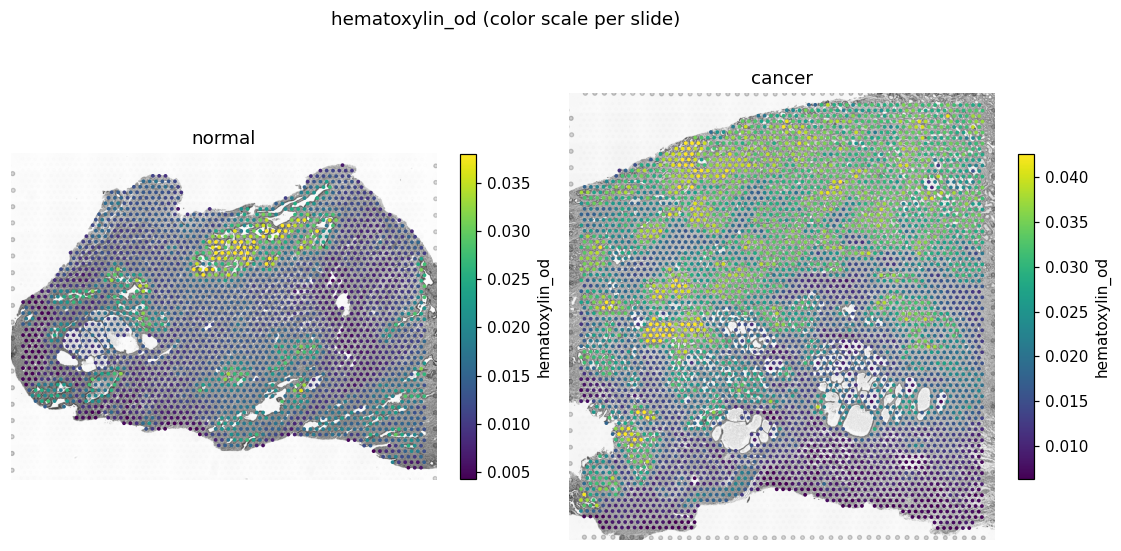

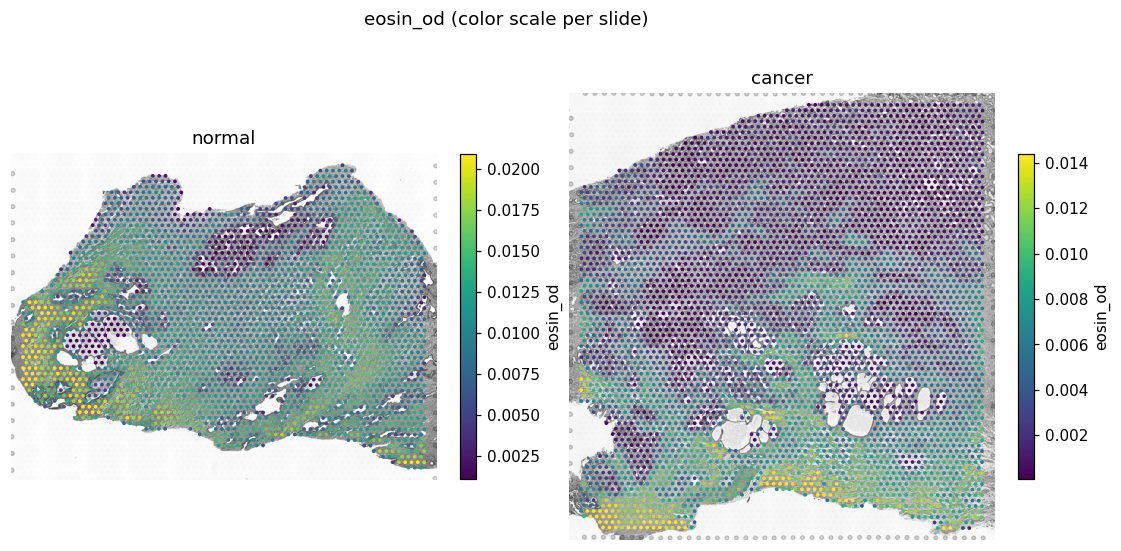

In [3]:
slides = io.read_slides(config)
img = io.read_table(config, "image_features.csv.gz", key="processed")
for feature in ["hematoxylin_od", "eosin_od"]:
    values = {s: img.loc[img["slide"] == s, feature].to_numpy() for s in io.SLIDES}
    fig = viz.paired_overlay(slides, values, feature, cmap="viridis", shared_scale=False)
    fig.suptitle(f"{feature} (color scale per slide)", y=1.0)
    viz.save(fig, fig_dir, f"03_{feature}_spatial.png")

## Within-slide correlations

Spearman correlation between each molecular feature and each image feature, computed separately in
each slide. Only genes detected in at least 10% of spots in *both* slides are included. A pair
counts as concordant when both correlations have the same sign and |rho| ≥ 0.2. Neighboring spots
are not independent, so we report correlation sizes and no p-values.

In [4]:
conc = io.read_table(config, "image_concordance.csv")
print(f"concordant pairs: {conc['concordant'].sum()} of {len(conc)}")
conc[conc["concordant"]].sort_values("min_abs_rho", ascending=False).head(15).reset_index(drop=True)

concordant pairs: 31 of 234


,feature,image_feature,rho_normal,rho_cancer,min_abs_rho,concordant
0,NKX3-1,gray_sd,0.349,0.346,0.346,True
1,CDH1,hematoxylin_od,0.326,0.345,0.326,True
2,NKX3-1,hematoxylin_od,0.310,0.556,0.310,True
3,score_down,gray_sd,0.371,0.304,0.304,True
4,CDH1,glcm_contrast,0.304,0.304,0.304,True
5,TMPRSS2,gray_sd,0.305,0.301,0.301,True
6,score_down,glcm_correlation,0.365,0.301,0.301,True
7,TMPRSS2,hematoxylin_od,0.297,0.491,0.297,True
8,KRT5,glcm_correlation,0.333,0.294,0.294,True
9,CDH1,gray_sd,0.341,0.290,0.290,True


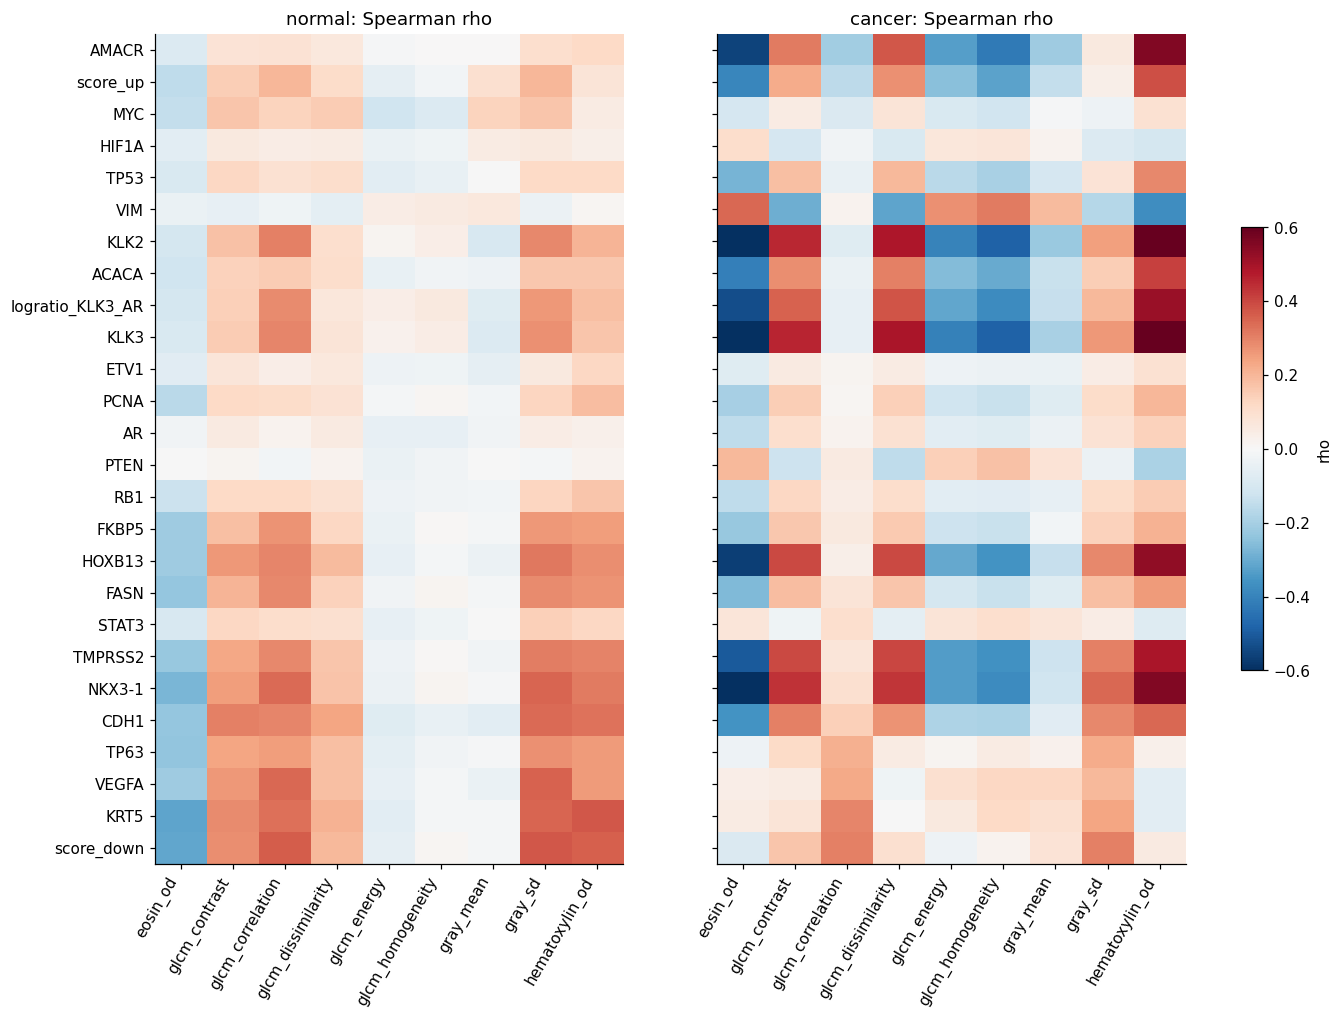

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * conc["feature"].nunique() + 2), sharey=True)
order = conc.groupby("feature")["rho_cancer"].mean().sort_values().index
for ax, slide in zip(axes, io.SLIDES):
    mat = conc.pivot(index="feature", columns="image_feature", values=f"rho_{slide}").loc[order]
    im = ax.imshow(mat.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=60, ha="right")
    ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.set_title(f"{slide}: Spearman rho")
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.02, label="rho")
viz.save(fig, fig_dir, "03_concordance_heatmaps.png")

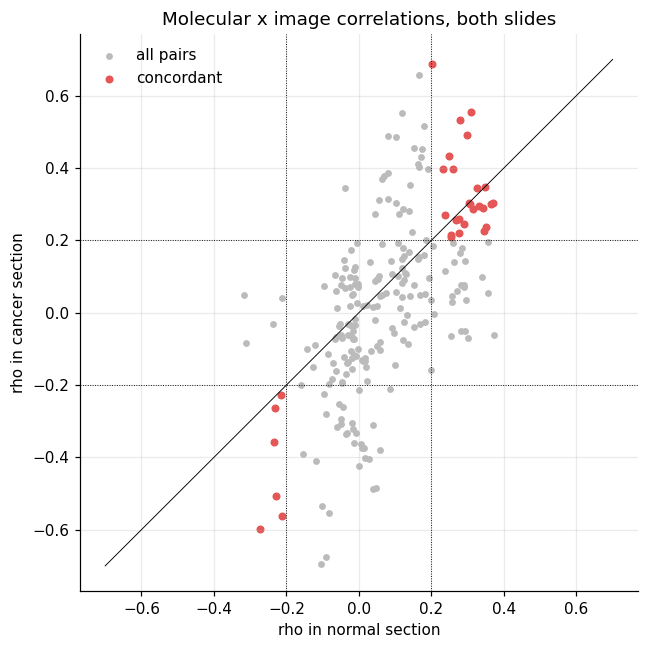

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(conc["rho_normal"], conc["rho_cancer"], s=12, color="#BBBBBB", label="all pairs")
hits = conc[conc["concordant"]]
ax.scatter(hits["rho_normal"], hits["rho_cancer"], s=18, color="#E45756", label="concordant")
lim = config["concordance"]["min_abs_rho"]
for v in (-lim, lim):
    ax.axhline(v, color="black", lw=0.6, ls=":")
    ax.axvline(v, color="black", lw=0.6, ls=":")
ax.plot([-0.7, 0.7], [-0.7, 0.7], color="black", lw=0.6)
ax.set_xlabel("rho in normal section")
ax.set_ylabel("rho in cancer section")
ax.set_title("Molecular x image correlations, both slides")
ax.legend(frameon=False)
fig.tight_layout()
viz.save(fig, fig_dir, "03_concordance_scatter.png")

The concordant pairs are dominated by luminal-epithelial genes (NKX3-1, HOXB13, TMPRSS2, KLK2/3,
CDH1). These rise with hematoxylin density and gray-level spread and fall with eosin density.
Gray-level spread is highest where a spot straddles a gland lumen (see the maps below), so in both
sections these genes mark glandular tissue rather than eosin-rich stroma. This is a
tissue-architecture signal, not a cancer signal. It is the same
composition axis seen in notebook 01, now confirmed from the image independently of the
expression data.

AMACR behaves differently. Within the cancer section it tracks hematoxylin density (rho 0.55) and
runs against eosin density (rho -0.55), so AMACR-high spots are nucleus-dense and stroma-poor. In
the normal section, where few spots express AMACR, both correlations are close to zero, so the
pair fails the both-slides rule. A link that appears only in the cancer section could reflect
tumor morphology, but this design cannot separate it from slide identity. It is worth testing on
sections with pathologist-annotated tumor glands and full-resolution images.

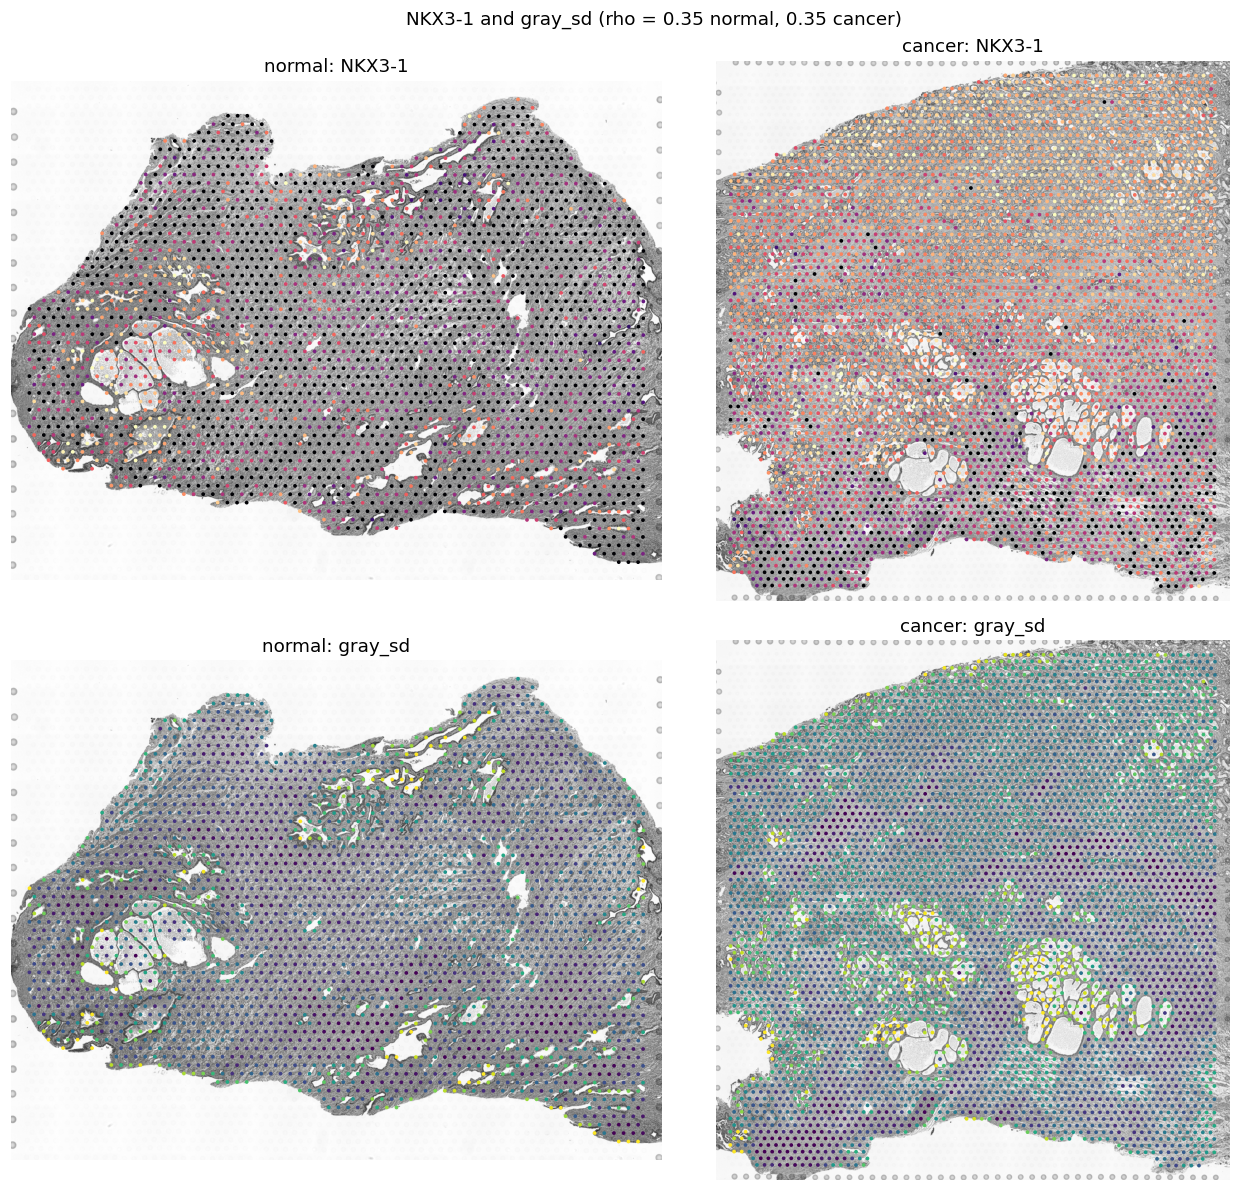

In [7]:
top = conc[conc["concordant"]].sort_values("min_abs_rho", ascending=False).iloc[0]
gene, feature = top["feature"], top["image_feature"]
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for col, slide in enumerate(io.SLIDES):
    adata = slides[slide]
    expr = np.asarray(adata[:, gene].X.todense()).ravel() if gene in adata.var_names \
        else None
    im_vals = img.loc[img["slide"] == slide, feature].to_numpy()
    viz.tissue_overlay(axes[0, col], adata, expr, cmap="magma",
                       vmax=np.percentile(expr, 99), title=f"{slide}: {gene}")
    viz.tissue_overlay(axes[1, col], adata, im_vals, cmap="viridis",
                       vmin=np.percentile(im_vals, 1), vmax=np.percentile(im_vals, 99),
                       title=f"{slide}: {feature}")
fig.suptitle(f"{gene} and {feature} (rho = {top['rho_normal']:.2f} normal, "
             f"{top['rho_cancer']:.2f} cancer)")
fig.tight_layout()
viz.save(fig, fig_dir, "03_top_pair_spatial.png")